In [1]:
import torch
import torchaudio
import matplotlib.pyplot as plt

In [2]:
# Load FocalCodec model
codec = torch.hub.load(
    repo_or_dir="lucadellalib/focalcodec",
    model="focalcodec",
    config="lucadellalib/focalcodec_50hz",
    force_reload=True,  # Fetch the latest FocalCodec version from Torch Hub
)
codec.eval().requires_grad_(False)

Downloading: "https://github.com/lucadellalib/focalcodec/zipball/main" to /home/enzo/.cache/torch/hub/main.zip


/home/enzo/vincent/wavtokenizer_test/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


FocalCodec(
  (encoder): WavLM(
    (feature_extractor): FeatureExtractor(
      (layers): ModuleList(
        (0): ConvBlock(
          (conv): Conv1d(1, 512, kernel_size=(10,), stride=(5,), bias=False)
          (dropout): Dropout(p=0.0, inplace=False)
          (norm): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
          (activation): GELU(approximate='none')
        )
        (1-4): 4 x ConvBlock(
          (conv): Conv1d(512, 512, kernel_size=(3,), stride=(2,), bias=False)
          (dropout): Dropout(p=0.0, inplace=False)
          (norm): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
          (activation): GELU(approximate='none')
        )
        (5-6): 2 x ConvBlock(
          (conv): Conv1d(512, 512, kernel_size=(2,), stride=(2,), bias=False)
          (dropout): Dropout(p=0.0, inplace=False)
          (norm): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
          (activation): GELU(approximate='none')
        )
      )
    )
    (norm): LayerNor

In [5]:
# Load and preprocess the input audio
audio_file = "data/a.wav"
sig, sample_rate = torchaudio.load(audio_file)
sig = torchaudio.functional.resample(sig, sample_rate, codec.sample_rate_input)

# Encode audio into tokens
toks = codec.sig_to_toks(sig)  # Shape: (batch, time)
print(toks.shape)
print(toks)

# Convert tokens to their corresponding binary spherical codes
codes = codec.toks_to_codes(toks)  # Shape: (batch, code_time, log2 codebook_size)
print(codes.shape)
print(codes)

# Decode tokens back into a waveform
rec_sig = codec.toks_to_sig(toks)

# Save the reconstructed audio
rec_sig = torchaudio.functional.resample(rec_sig, codec.sample_rate_output, sample_rate)
torchaudio.save("result/test_focal.wav", rec_sig, sample_rate)

torch.Size([1, 99])
tensor([[4384, 1150, 3370, 4578, 7470, 4590, 1318, 6971, 5480, 7462, 6946, 5422,
         2351, 4472, 7470, 5088, 5550, 6443, 2338, 7470, 6625, 1340, 6443, 4451,
         7598, 4964, 7470, 6447, 4456, 7598, 7012, 7470, 6443, 4456, 7598, 6512,
         5422, 6955, 6434, 7470, 4384, 5422, 6443,  296, 3374,  886, 3374, 6447,
          300, 3374, 4918, 1326, 4911,  302, 7462, 4902, 5550, 6959,  356, 7470,
         4902, 5550, 6959, 4454, 7471, 4902, 7598, 6959, 4450, 7470, 4966, 7598,
         6447, 4420, 7470, 5094, 7598, 4643, 5420, 5422, 5094, 3374, 6510, 4388,
         7466, 4980, 5418, 4394, 4386, 5422, 4978, 3498, 4395, 2434, 5422, 6522,
         5422, 6511, 7472]])
torch.Size([1, 99, 13])
tensor([[[ 0.2774, -0.2774, -0.2774,  ..., -0.2774, -0.2774, -0.2774],
         [-0.2774, -0.2774,  0.2774,  ...,  0.2774,  0.2774, -0.2774],
         [-0.2774,  0.2774,  0.2774,  ..., -0.2774,  0.2774, -0.2774],
         ...,
         [ 0.2774, -0.2774,  0.2774,  ...,  0.2774, 

torch.return_types.sort(
values=tensor([ 296,  300,  302,  356,  886, 1150, 1318, 1326, 1340, 2338, 2351, 2434,
        3370, 3374, 3374, 3374, 3374, 3498, 4384, 4384, 4386, 4388, 4394, 4395,
        4420, 4450, 4451, 4454, 4456, 4456, 4472, 4578, 4590, 4643, 4902, 4902,
        4902, 4911, 4918, 4964, 4966, 4978, 4980, 5088, 5094, 5094, 5418, 5420,
        5422, 5422, 5422, 5422, 5422, 5422, 5422, 5480, 5550, 5550, 5550, 6434,
        6443, 6443, 6443, 6443, 6447, 6447, 6447, 6510, 6511, 6512, 6522, 6625,
        6946, 6955, 6959, 6959, 6959, 6971, 7012, 7462, 7462, 7466, 7470, 7470,
        7470, 7470, 7470, 7470, 7470, 7470, 7470, 7471, 7472, 7598, 7598, 7598,
        7598, 7598, 7598]),
indices=tensor([43, 48, 53, 58, 45,  1,  6, 51, 21, 18, 12, 93,  2, 49, 81, 46, 44, 91,
         0, 40, 88, 83, 87, 92, 73, 68, 23, 63, 28, 33, 13,  3,  5, 77, 55, 60,
        65, 52, 50, 25, 70, 90, 85, 15, 80, 75, 86, 78, 79, 11, 41, 36, 89, 94,
        96,  8, 16, 61, 56, 38, 32, 42, 22, 17, 72, 

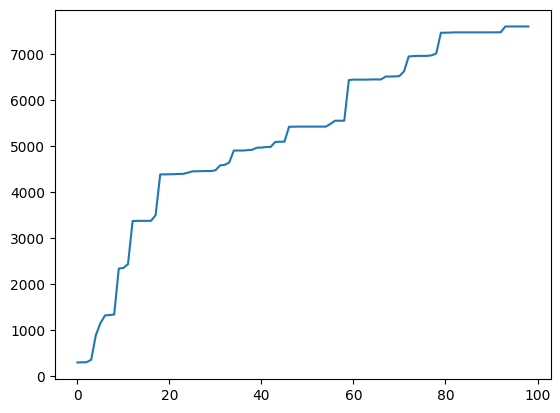

In [12]:
print(torch.sort(toks[0]))
plt.plot(torch.sort(toks[0])[0])